# Long-term wealth, from first principles

**The question:** a long-term investor keeps the compound growth of their wealth. Can a neural network, trained on exactly that quantity after trading costs, build a better long-only portfolio than simply holding the market?

This notebook builds the three ideas behind the Deep Growth Network in a few lines each, then shows the real out-of-sample results:

1. Growth is not average return: volatility drains compounding.
2. The growth-optimal (Kelly) mix, found by gradient ascent in PyTorch.
3. Why trading costs teach a policy to trade only part of the way to its target.
4. The real study: 30 US industries, out of sample from 1960.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

torch.manual_seed(0)
rng = np.random.default_rng(0)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False})

## 1. Growth is not average return

Two made-up assets (the same as the website's toy): a steady market with a 10% average yearly return and 16% volatility, and a riskier industry with 13% and 30%, correlation 0.6.

For a portfolio with average return $\mu$ and volatility $\sigma$, wealth compounds at roughly $g \approx \mu - \sigma^2/2$ a year. The average return rises all the way to 100% risky; the growth of wealth peaks well before.

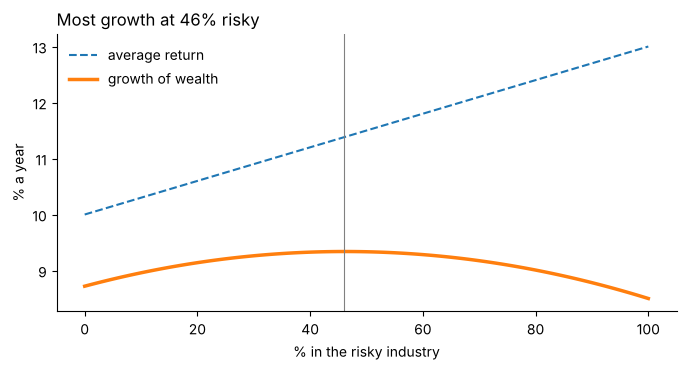

$1 after 66 years: $273 at 100% risky, $475 at 46% risky


In [2]:
mu = np.array([0.10, 0.13]); sigma = np.array([0.16, 0.30]); rho = 0.6
cov = np.array([[sigma[0] ** 2, rho * sigma[0] * sigma[1]], [rho * sigma[0] * sigma[1], sigma[1] ** 2]])
x = np.linspace(0, 1, 101)
W = np.stack([1 - x, x], 1)
mean = W @ mu
var = np.einsum("ki,ij,kj->k", W, cov, W)
growth = mean - var / 2
best = x[growth.argmax()]
plt.plot(100 * x, 100 * mean, "--", label="average return")
plt.plot(100 * x, 100 * growth, lw=2.5, label="growth of wealth")
plt.axvline(100 * best, color="grey", lw=0.8)
plt.xlabel("% in the risky industry"); plt.ylabel("% a year"); plt.legend(frameon=False)
plt.title(f"Most growth at {100 * best:.0f}% risky", loc="left"); plt.show()
print(f"$1 after 66 years: ${np.exp(66 * growth[-1]):,.0f} at 100% risky, ${np.exp(66 * growth.max()):,.0f} at {100 * best:.0f}% risky")

A simulation agrees: draw 66 years of monthly returns many times. The *average* final wealth rewards risk, but the *typical* (median) investor ends up richer with the growth-optimal mix. A long-term investor lives one path, so the median, and the growth rate behind it, is what matters.

In [3]:
def simulate_wealth(share, years=66, paths=20000, seed=1):
    r = np.random.default_rng(seed).multivariate_normal(mu / 12, cov / 12, size=(paths, 12 * years))
    port = (1 - share) * r[..., 0] + share * r[..., 1]          # rebalanced monthly to the same mix
    return np.exp(np.log1p(port).sum(1))

for share in (best, 1.0):
    w = simulate_wealth(share)
    print(f"{100 * share:3.0f}% risky: mean final wealth ${w.mean():>9,.0f}   median ${np.median(w):>7,.0f}")

 46% risky: mean final wealth $    1,689   median $    460


100% risky: mean final wealth $    4,148   median $    267


## 2. The Kelly mix, found by gradient ascent

The Deep Growth Network is trained on the average monthly log growth of wealth, $\mathbb{E}[\log(1 + w^\top r)]$, the Kelly criterion. With one free parameter, gradient ascent in PyTorch finds the growth-optimal mix of a simulated sample: the same answer as trying every mix on that sample, and close to the formula above (which is the continuous-time approximation).

In [4]:
R = torch.tensor(rng.multivariate_normal(mu / 12, cov / 12, size=1_000_000), dtype=torch.float32)
logit = torch.zeros(1, requires_grad=True)                      # share = sigmoid(logit), starts at 50%
opt = torch.optim.Adam([logit], lr=0.05)
for step in range(300):
    share = torch.sigmoid(logit)
    loss = -torch.log1p((1 - share) * R[:, 0] + share * R[:, 1]).mean()
    opt.zero_grad(); loss.backward(); opt.step()
grid = torch.linspace(0, 1, 201)
on_sample = torch.stack([torch.log1p((1 - s) * R[:, 0] + s * R[:, 1]).mean() for s in grid])
print(f"gradient ascent: {100 * torch.sigmoid(logit).item():.1f}% risky; every mix tried on the same sample: "
      f"{100 * grid[on_sample.argmax()].item():.1f}%; continuous-time formula: {100 * best:.0f}%")

gradient ascent: 44.4% risky; every mix tried on the same sample: 44.5%; continuous-time formula: 46%


## 3. Trading costs teach patience

Between decisions, prices move the holdings away from the target. Trading back costs money; staying away from the best mix costs growth. The network's second head chooses a *trade fraction* $\kappa$: each month it trades $\kappa$ of the gap between today's holdings and its target ($\kappa = 0$ is buy and hold, $\kappa = 1$ a full rebalance).

Below, the same simulator the network learns in (holdings drift with prices, every unit traded costs $c$), with the target fixed at the growth-optimal mix. Every $\kappa$ sees the same simulated returns, so the differences are not noise. With free trading, a full rebalance is best; as costs rise, the best $\kappa$ falls. The network has to learn this, from the wealth it ends up with.

In [5]:
def growth_with(kappa, cost, R, target):
    """Average yearly log growth of a policy that trades kappa of the gap to the target each month."""
    w = torch.full((R.shape[0],), target)                        # start at the target
    total = torch.zeros(R.shape[0])
    for t in range(R.shape[1]):
        w_new = w + kappa * (target - w)
        traded = 2 * (w_new - w).abs()                           # sell one asset, buy the other
        g = (1 - w_new) * R[:, t, 0] + w_new * R[:, t, 1]
        total = total + torch.log1p(-cost * traded) + torch.log1p(g)
        w = w_new * (1 + R[:, t, 1]) / (1 + g)                   # prices move the holdings
    return 12 * total.mean() / R.shape[1]

paths = torch.tensor(rng.multivariate_normal(mu / 12, cov / 12, size=(4000, 120)), dtype=torch.float32)
kappas = [0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
rows = {}
for bps in (0, 10, 50, 200):
    g = np.array([growth_with(k, bps / 1e4, paths, float(best)).item() for k in kappas])
    rows[f"{bps} bps"] = 1e4 * (g - g.max())                      # basis points a year below the best kappa
table = pd.DataFrame(rows, index=pd.Index(kappas, name="kappa")).round(1)
print("Growth lost against the best trade fraction, basis points a year (0.0 marks the best):")
table

Growth lost against the best trade fraction, basis points a year (0.0 marks the best):


,0 bps,10 bps,50 bps,200 bps
kappa,,,,
0.02,-2.3,-1.1,-0.0,0.0
0.05,-1.2,-0.3,0.0,-3.1
0.10,-0.7,0.0,-0.7,-7.4
0.20,-0.3,-0.0,-2.1,-14.0
0.35,-0.2,-0.3,-4.0,-22.2
0.50,-0.1,-0.6,-5.9,-29.8
0.75,-0.0,-1.1,-9.0,-42.7
1.00,0.0,-1.9,-12.7,-57.3


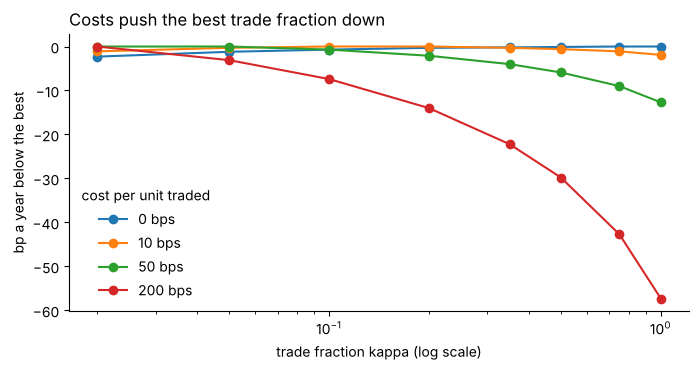

In [6]:
for col in table:
    plt.plot(table.index, table[col], marker="o", label=col)
plt.xscale("log"); plt.xlabel("trade fraction kappa (log scale)"); plt.ylabel("bp a year below the best")
plt.legend(title="cost per unit traded", frameon=False); plt.title("Costs push the best trade fraction down", loc="left"); plt.show()

The gaps are small per year but they compound: over 66 years, 10 basis points a year is about 7% of final wealth. The real network learns $\kappa$ from its features each month instead of using one number, inside a simulator that charges the study's 10 bps for every trade.

## 4. The real study

30 US industry portfolios from Kenneth French's library, out of sample from January 1960, long-only, fully invested, 10 bps per trade. The protocol, the comparisons and the decision rule were committed to git before the network was run out of sample (`docs/wealth_protocol.md`). Everything below is read from committed results.

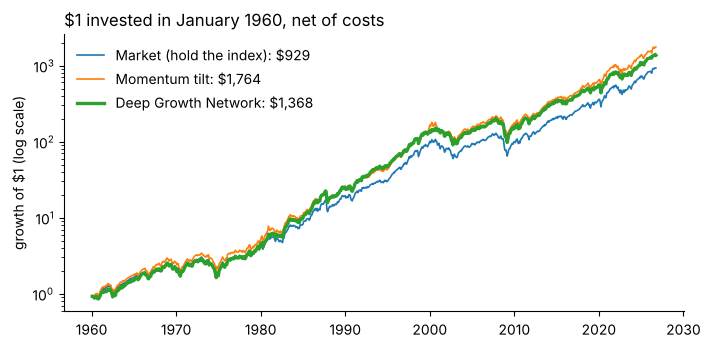

Pre-registered test, network minus market: +0.58% a year, Newey-West t 1.40, 95% interval -0.07% to +1.50%: no detectable difference.
What it chose: a median trade fraction of 81% (training starts it at 25%), 155% of the portfolio traded a year.


In [7]:
summary = json.loads((ROOT / "reports/wealth/summary.json").read_text())
labels = {"market": "Market (hold the index)", "momentum_tilt": "Momentum tilt", "deep": "Deep Growth Network"}
for name, label in labels.items():
    df = pd.read_parquet(ROOT / f"reports/results/wealth/{name}.parquet")
    wealth = (1 + df["net"]).cumprod()
    plt.plot(wealth.index, wealth.values, lw=2.4 if name == "deep" else 1.2, label=f"{label}: ${wealth.iloc[-1]:,.0f}")
plt.yscale("log"); plt.ylabel("growth of $1 (log scale)"); plt.legend(frameon=False)
plt.title("$1 invested in January 1960, net of costs", loc="left"); plt.show()
c = summary["comparisons"]["deep - market"]
print(f"Pre-registered test, network minus market: {100 * c['diff_log_growth']:+.2f}% a year, "
      f"Newey-West t {c['t_nw']:.2f}, 95% interval {100 * c['ci_low']:+.2f}% to {100 * c['ci_high']:+.2f}%: {c['verdict']}.")
tf, deep = summary["deep_trade_fraction"], summary["performance"]["deep"]
print(f"What it chose: a median trade fraction of {100 * tf['median']:.0f}% (training starts it at 25%), "
      f"{100 * deep['turnover_per_year']:.0f}% of the portfolio traded a year.")

In [8]:
perf = pd.DataFrame(summary["performance"]).T
cols = ["terminal_wealth", "cagr", "volatility", "sharpe", "max_drawdown", "turnover_per_year", "active_share"]
perf.loc[[n for n in ["market", "equal_weight", "min_variance", "risk_parity", "growth_classical", "momentum_tilt", "deep"] if n in perf.index], cols].astype(float).round(3)

,terminal_wealth,cagr,volatility,sharpe,max_drawdown,turnover_per_year,active_share
market,928.769,0.108,0.153,0.470,-0.500,0.037,0.000
equal_weight,1376.518,0.114,0.163,0.487,-0.526,0.056,0.429
min_variance,1180.143,0.112,0.129,0.560,-0.406,0.203,0.661
risk_parity,1418.152,0.115,0.153,0.511,-0.494,0.065,0.402
growth_classical,904.809,0.107,0.153,0.466,-0.482,0.090,0.460
momentum_tilt,1763.648,0.118,0.156,0.527,-0.461,1.097,0.238
deep,1368.243,0.114,0.151,0.513,-0.519,1.550,0.316


## What to take away

* **Train on what the investor keeps.** The loss is the growth of wealth after costs, so volatility and trading are penalised in the units that matter, not through a hand-set risk or turnover penalty.
* **Start from the market and earn every deviation.** The tilt head starts at zero, so the untrained network is the index fund; training moves it only where that grew wealth on held-out years.
* **Holding still is a decision.** The trade fraction lets the network learn how much patience costs and pays; section 4 prints what it chose.
* **Judge it by a rule fixed in advance.** The verdict above comes from the pre-registered test, whatever it says.

Read next: `reports/wealth/research_note.md` (the write-up) and `reports/wealth/results.md` (every table).